# OPERATION: BLANK MAP — LUCBAN, QUEZON EDITION
### CPE15 Final Examination | Individual Investigator's Notebook

**Case CPE15-LUC-001** | Student ID: ________________  | Section: ________________

Real Lucban barangay names and approximate reference points; **simulated** 350 m study catchments, facilities, household access, risk and service evidence. Read `STUDENT_CASEFILE.md` and `data/GEOGRAPHIC_SOURCES.md` before relying on any number here.

> **Disclosure.** The twelve catchment polygons are synthetic 350 m teaching buffers around approximate locality anchors. They are **not** official barangay boundaries. All facility, access, risk, request, distance and priority values are simulated for classroom use and are **not** LGU, PSA, CBMS, hazard or telecommunications data.

## 0. Workspace and reproducibility

The notebook resolves the evidence folder from either the project root or the `answers/` directory, then asserts that all six source files are present. Source evidence is read-only throughout.

In [1]:
import os
import re
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

HERE = Path.cwd()
CANDIDATES = [HERE / "data", HERE.parent / "data", Path("data")]
DATA_DIR = next((p for p in CANDIDATES if (p / "zones.geojson").exists()), None)
assert DATA_DIR is not None, "Could not locate the evidence data/ folder."
OUT_DIR = HERE
assert OUT_DIR.name == "answers" or (OUT_DIR / "data").exists(), "Run from the project root or answers/."

EXPECTED = ["zones.geojson", "household_access.csv", "risk_index.csv",
            "service_requests.sqlite", "facilities.csv", "field_notes.txt"]
missing = [n for n in EXPECTED if not (DATA_DIR / n).exists()]
assert not missing, f"Missing evidence file(s): {missing}"

print(f"Evidence folder : {DATA_DIR.resolve()}")
print(f"Output folder   : {OUT_DIR.resolve()}")
print("All six evidence files present. Sources will only be read.")

Evidence folder : /home/rollie/dev/CPE15/activity/final-project/Operation Blank Map - STUDENT PACKAGE/data
Output folder   : /home/rollie/dev/CPE15/activity/final-project/Operation Blank Map - STUDENT PACKAGE/answers
All six evidence files present. Sources will only be read.


In [2]:
import geopandas as gpd
import folium
from branca.colormap import LinearColormap

METRIC_CRS = "EPSG:32651"
WGS84 = "EPSG:4326"
print("GeoPandas", gpd.__version__, "| Folium", folium.__version__)
print("Metric CRS for distances:", METRIC_CRS, "(UTM zone 51N, metres)")

GeoPandas 1.1.3 | Folium 0.20.0
Metric CRS for distances: EPSG:32651 (UTM zone 51N, metres)


## 1. Case log | Evidence reliability

Six classes of defect are present in the package: an inconsistent zone-code form (`A-03` versus `A03`), an exact duplicate household row, a missing access count, a logically impossible access count, a conflicting duplicate risk record, and duplicate request IDs in SQLite. The field bulletin authorises repairs for four of them (FN-01 to FN-04). Everything else is retained as-is and reported.

The cell below loads each source **as text** and runs explicit integrity checks so that the findings are traceable to code rather than assertion.

In [3]:
raw_household = pd.read_csv(DATA_DIR / "household_access.csv", dtype=str)
raw_risk = pd.read_csv(DATA_DIR / "risk_index.csv", dtype=str)
raw_facilities = pd.read_csv(DATA_DIR / "facilities.csv", dtype=str)
with sqlite3.connect(DATA_DIR / "service_requests.sqlite") as con:
    raw_requests = pd.read_sql_query("SELECT * FROM requests", con)

print("household_access :", raw_household.shape)
print("risk_index       :", raw_risk.shape)
print("facilities       :", raw_facilities.shape)
print("requests         :", raw_requests.shape)
print()
print(raw_household.head(15).to_string(index=False))
print()
print(raw_risk.to_string(index=False))
print()
print("request statuses:", raw_requests["status"].value_counts().to_dict())
print("request types   :", raw_requests["request_type"].value_counts().to_dict())
print("raw request zone codes:", sorted(raw_requests["zone_code"].unique()))

household_access : (13, 3)
risk_index       : (13, 2)
facilities       : (5, 5)
requests         : (397, 5)

zone_code total_households households_with_access
      A01              850                  520.0
      A02              700                  238.0
     A-03              500                  228.0
      A04              350                  260.0
      A05              460                  325.0
      A06              820                    NaN
      A07             1100                  400.0
      A07             1100                  400.0
      A08              650                  150.0
      A09              500                  220.0
      A10              410                  300.0
      A11              780                 1220.0
      A12             1200                  750.0

zone_code risk_score
      A01         40
      A02         80
      A03         66
      A04         25
      A05         40
      A06         48
      A07         55
      A08         77
 

In [4]:
findings = []

zone_forms = {
    "household_access.csv": sorted(raw_household["zone_code"].unique()),
    "risk_index.csv": sorted(raw_risk["zone_code"].unique()),
    "service_requests.sqlite": sorted(raw_requests["zone_code"].unique()),
}
alias_present = {name: ("A-03" in vals) for name, vals in zone_forms.items()}
findings.append({
    "issue_id": "D1",
    "issue": "Zone-code variant A-03 used instead of A03",
    "evidence": f"Present in: {[k for k, v in alias_present.items() if v]}",
    "severity": "High - breaks joins and SQL grouping",
    "repair": "FN-01: normalise A-03 to A03 in all files",
})

dup_hh = raw_household[raw_household.duplicated(keep=False)]
findings.append({
    "issue_id": "D2",
    "issue": "Exact duplicate household record for A07",
    "evidence": f"{len(dup_hh)} identical rows; {raw_household['zone_code'].duplicated().sum()} duplicated zone row(s)",
    "severity": "High - would double-count A07 households",
    "repair": "Drop exact duplicate; recompute from unique zone rows (field note: count a household once)",
})

missing_hh = raw_household[raw_household["households_with_access"].isna()]
findings.append({
    "issue_id": "D3",
    "issue": "Missing households_with_access value",
    "evidence": f"{len(missing_hh)} blank row(s): {missing_hh['zone_code'].tolist()}",
    "severity": "High - cannot compute service gap",
    "repair": "FN-02: A06 = 350 (do not treat blank as zero)",
})

raw_household_num = raw_household.assign(
    total=pd.to_numeric(raw_household["total_households"], errors="coerce"),
    access=pd.to_numeric(raw_household["households_with_access"], errors="coerce"),
)
impossible = raw_household_num[raw_household_num["access"] > raw_household_num["total"]]
findings.append({
    "issue_id": "D4",
    "issue": "Access count exceeds total households (logically impossible)",
    "evidence": "; ".join(f"{r.zone_code}: {r.access:.0f} access / {r.total:.0f} total"
                          for r in impossible.itertuples()),
    "severity": "High - produces negative service gap",
    "repair": "FN-03: A11 access superseded by 220",
})

dup_risk = raw_risk[raw_risk["zone_code"].duplicated(keep=False)]
findings.append({
    "issue_id": "D5",
    "issue": "Conflicting duplicate risk record",
    "evidence": "; ".join(f"{r.zone_code}={r.risk_score}" for r in dup_risk.itertuples()),
    "severity": "High - one value per zone required",
    "repair": "FN-04: A09 = 72 is current; 96 is obsolete",
})

dup_req = raw_requests[raw_requests["request_id"].duplicated(keep=False)]
findings.append({
    "issue_id": "D6",
    "issue": "Duplicate request_id rows in SQLite",
    "evidence": f"{raw_requests['request_id'].duplicated().sum()} duplicate row(s): "
                f"{sorted(dup_req['request_id'].unique().tolist())}",
    "severity": "Medium - inflates raw request counts",
    "repair": "Count DISTINCT request_id; filter status verified/open",
})

findings.append({
    "issue_id": "D7",
    "issue": "Ineligible request statuses present",
    "evidence": raw_requests["status"].value_counts().to_dict(),
    "severity": "Medium - cancelled/invalid requests are not demand",
    "repair": "Keep only status in {verified, open}, distinct request_id",
})

findings_df = pd.DataFrame(findings)
print(findings_df.to_string(index=False))

issue_id                                                        issue                                                             evidence                                           severity                                                                                     repair
      D1                   Zone-code variant A-03 used instead of A03      Present in: ['household_access.csv', 'service_requests.sqlite']               High - breaks joins and SQL grouping                                                  FN-01: normalise A-03 to A03 in all files
      D2                     Exact duplicate household record for A07                           2 identical rows; 1 duplicated zone row(s)           High - would double-count A07 households Drop exact duplicate; recompute from unique zone rows (field note: count a household once)
      D3                         Missing households_with_access value                                              1 blank row(s): ['A06']                  H

### 1.1 Parsing the verified field bulletin with native Python

The bulletin is read line by line and matched with regular expressions. Each `FN-xx VERIFIED` statement becomes a structured repair instruction; unmarked note lines are retained as interpretation rules but are **not** used to alter source values.

In [5]:
notes_text = (DATA_DIR / "field_notes.txt").read_text(encoding="utf-8")
lines = [line.strip() for line in notes_text.splitlines() if line.strip()]

verified_lines = [line for line in lines if re.match(r"^FN-\d+\s+VERIFIED:", line)]
note_lines = [line for line in lines if line.upper().startswith("NOTE:")]

parsed = []
for line in verified_lines:
    fn_id = re.match(r"^(FN-\d+)", line).group(1)
    body = line.split("VERIFIED:", 1)[1].strip()
    parsed.append({"fn_id": fn_id, "statement": body})

parsed_df = pd.DataFrame(parsed)
print("VERIFIED bulletins found:", len(parsed_df))
print(parsed_df.to_string(index=False))
print()
print("Interpretation notes (not repairs):")
for n in note_lines:
    print(" -", n)

VERIFIED bulletins found: 4
fn_id                                                                        statement
FN-01            The zone code A-03 is an alternate entry for A03 in ALL source files.
FN-02                         The missing households_with_access value for A06 is 350.
FN-03    The erroneous households_with_access value 1220 for A11 is superseded by 220.
FN-04 For A09, risk_score 72 is current; risk_score 96 is an obsolete duplicate entry.

Interpretation notes (not repairs):
 - NOTE: A household with access must be counted only once. Duplicate records are not new households.
 - NOTE: Only service requests with status "verified" or "open" count as active demand. Count distinct request_id values.
 - NOTE: For equal priorities, apply ascending zone_id to break ties.
 - NOTE: The zones.geojson shapes are synthetic 350-meter study catchments around approximate
 - NOTE: Facility points represent fictional assistance hubs, NOT actual LGU facility inventories.
 - NOTE: All 

In [6]:
def parse_repairs(parsed):
    repairs = []
    for row in parsed.itertuples():
        s = row.statement
        if re.search(r"alternate entry", s, re.I):
            codes = re.findall(r"A-\d{2}|A\d{2}", s)
            repairs.append({"fn_id": row.fn_id, "action": "zone_alias",
                            "field": "zone_code", "old": codes[0], "new": codes[1] if len(codes) > 1 else None})
        elif re.search(r"missing households_with_access", s, re.I):
            zone = re.search(r"\bA-?\d{2}\b", s).group(0)
            value = float(re.search(r"\bis\s+([\d.]+)", s).group(1))
            repairs.append({"fn_id": row.fn_id, "action": "set_access",
                            "field": "households_with_access", "zone": zone, "new": value})
        elif re.search(r"erroneous households_with_access", s, re.I):
            zone = re.search(r"\bA-?\d{2}\b", s).group(0)
            nums = [float(x) for x in re.findall(r"\b(\d{2,5})\b", s)]
            repairs.append({"fn_id": row.fn_id, "action": "replace_access",
                            "field": "households_with_access", "zone": zone,
                            "old": nums[0], "new": max(nums[1:]) if len(nums) > 1 else None})
        elif re.search(r"risk_score", s, re.I) and re.search(r"obsolete", s, re.I):
            zone = re.search(r"\bA-?\d{2}\b", s).group(0)
            nums = [float(x) for x in re.findall(r"\b(\d{2,3})\b", s)]
            repairs.append({"fn_id": row.fn_id, "action": "replace_risk",
                            "field": "risk_score", "zone": zone,
                            "old": max(nums), "new": min(nums)})
    return pd.DataFrame(repairs)


repairs_df = parse_repairs(parsed_df)
print(repairs_df.to_string(index=False))

ALIAS = repairs_df.loc[repairs_df.action == "zone_alias", "old"].iloc[0]
ACCESS_FIX = {r.zone: r.new for r in repairs_df[repairs_df.action == "set_access"].itertuples()}
ACCESS_FIX.update({r.zone: r.new for r in repairs_df[repairs_df.action == "replace_access"].itertuples()})
RISK_FIX = {r.zone: r.new for r in repairs_df[repairs_df.action == "replace_risk"].itertuples()}
print("\nParsed repairs ->", {"alias": ALIAS, "access": ACCESS_FIX, "risk": RISK_FIX})

fn_id         action                  field       old     new zone
FN-01     zone_alias              zone_code      A-03     A03  NaN
FN-02     set_access households_with_access       NaN 350.000  A06
FN-03 replace_access households_with_access 1,220.000 220.000  A11
FN-04   replace_risk             risk_score    96.000  72.000  A09

Parsed repairs -> {'alias': 'A-03', 'access': {'A06': 350.0, 'A11': 220.0}, 'risk': {'A09': 72.0}}


### 1.2 Applying the repairs and preserving a correction log

The original DataFrames are never mutated. Each repair is applied to a copy, and the log records the file, zone, field, old value, new value, authority and rationale.

In [7]:
log_rows = []
log_rows.append({"source": "household_access.csv + risk_index.csv + service_requests.sqlite",
                 "zone": "A-03/A03", "field": "zone_code", "old_value": "A-03", "new_value": "A03",
                 "authority": "FN-01", "rationale": "Alternate entry for the same zone in all source files"})

household = raw_household.copy()
household["zone_code"] = household["zone_code"].str.replace(ALIAS, "A03", regex=False)
before = len(household)
household = household.drop_duplicates()
for r in household[household.duplicated("zone_code", keep=False)].itertuples():
    pass
log_rows.append({"source": "household_access.csv", "zone": "A07", "field": "row", "old_value": f"{before} rows",
                 "new_value": f"{len(household)} rows", "authority": "Field note: count a household once",
                 "rationale": "Removed exact duplicate A07 row"})

household["total_households"] = pd.to_numeric(household["total_households"], errors="raise")
household["households_with_access"] = pd.to_numeric(household["households_with_access"], errors="coerce")
for zone, value in ACCESS_FIX.items():
    old = household.loc[household.zone_code == zone, "households_with_access"]
    old_display = "blank" if old.isna().all() else f"{old.iloc[0]:.0f}"
    household.loc[household.zone_code == zone, "households_with_access"] = value
    log_rows.append({"source": "household_access.csv", "zone": zone, "field": "households_with_access",
                     "old_value": old_display, "new_value": f"{value:.0f}",
                     "authority": repairs_df.loc[repairs_df.new == value, "fn_id"].iloc[0] if (repairs_df.new == value).any() else "FN",
                     "rationale": "Verified field-note repair"})

risk = raw_risk.copy()
risk["zone_code"] = risk["zone_code"].str.replace(ALIAS, "A03", regex=False)
risk["risk_score"] = pd.to_numeric(risk["risk_score"], errors="raise")
risk = risk.drop_duplicates()
for zone, value in RISK_FIX.items():
    old = risk.loc[risk.zone_code == zone, "risk_score"].tolist()
    risk = risk[risk.zone_code != zone]
    risk = pd.concat([risk, pd.DataFrame([{"zone_code": zone, "risk_score": value}])], ignore_index=True)
    log_rows.append({"source": "risk_index.csv", "zone": zone, "field": "risk_score",
                     "old_value": "/".join(f"{v:.0f}" for v in old), "new_value": f"{value:.0f}",
                     "authority": repairs_df.loc[repairs_df.new == value, "fn_id"].iloc[0] if (repairs_df.new == value).any() else "FN",
                     "rationale": "Kept the current value; removed obsolete duplicate"})
risk = risk.drop_duplicates(subset="zone_code", keep="last").reset_index(drop=True)

correction_log = pd.DataFrame(log_rows)
print(correction_log.to_string(index=False))

                                                         source     zone                  field old_value new_value                          authority                                             rationale
household_access.csv + risk_index.csv + service_requests.sqlite A-03/A03              zone_code      A-03       A03                              FN-01 Alternate entry for the same zone in all source files
                                           household_access.csv      A07                    row   13 rows   12 rows Field note: count a household once                       Removed exact duplicate A07 row
                                           household_access.csv      A06 households_with_access     blank       350                              FN-02                            Verified field-note repair
                                           household_access.csv      A11 households_with_access      1220       220                              FN-03                            Ve

In [8]:
assert household["zone_code"].is_unique, "Household table must be one row per zone."
assert risk["zone_code"].is_unique, "Risk table must be one row per zone."
assert (household["households_with_access"] <= household["total_households"]).all(), "Access > total remains."
assert household["households_with_access"].notna().all(), "Missing access remains."
print("Post-repair integrity checks passed:",
      f"{len(household)} household rows, {len(risk)} risk rows, access <= total for all zones.")
print(household.sort_values("zone_code").to_string(index=False))
print()
print(risk.sort_values("zone_code").to_string(index=False))

Post-repair integrity checks passed: 12 household rows, 12 risk rows, access <= total for all zones.
zone_code  total_households  households_with_access
      A01               850                 520.000
      A02               700                 238.000
      A03               500                 228.000
      A04               350                 260.000
      A05               460                 325.000
      A06               820                 350.000
      A07              1100                 400.000
      A08               650                 150.000
      A09               500                 220.000
      A10               410                 300.000
      A11               780                 220.000
      A12              1200                 750.000

zone_code  risk_score
      A01      40.000
      A02      80.000
      A03      66.000
      A04      25.000
      A05      40.000
      A06      48.000
      A07      55.000
      A08      77.000
      A09      72.000
  

### 1.3 SQL extraction of eligible demand

Demand is **distinct request IDs** whose status is `verified` or `open`. The query normalises the `A-03` alias inside SQL, filters status, and counts distinct IDs; a second audit query shows how much the un-filtered count would have overstated demand.

In [9]:
zone_expr = f"CASE WHEN zone_code = '{ALIAS}' THEN 'A03' ELSE zone_code END"

eligible_sql = f'''
SELECT {zone_expr} AS zone_code,
       COUNT(DISTINCT request_id) AS valid_requests
FROM requests
WHERE status IN ('verified', 'open')
GROUP BY {zone_expr}
ORDER BY zone_code;
'''

raw_sql = f'''
SELECT {zone_expr} AS zone_code,
       COUNT(*) AS all_rows,
       COUNT(DISTINCT request_id) AS distinct_ids,
       SUM(CASE WHEN status IN ('verified','open') THEN 1 ELSE 0 END) AS eligible_rows
FROM requests
GROUP BY {zone_expr}
ORDER BY zone_code;
'''

with sqlite3.connect(DATA_DIR / "service_requests.sqlite") as con:
    requests_by_zone = pd.read_sql_query(eligible_sql, con)
    sql_audit = pd.read_sql_query(raw_sql, con)

print("Eligible distinct requests per zone (SQL):")
print(requests_by_zone.to_string(index=False))
print()
print("Audit of all rows vs eligible rows:")
print(sql_audit.to_string(index=False))

assert requests_by_zone["zone_code"].is_unique
assert set(requests_by_zone["zone_code"]).issubset(set(household["zone_code"]))
print("\nAll SQL zone codes resolve to a household zone.")

Eligible distinct requests per zone (SQL):
zone_code  valid_requests
      A01              23
      A02              29
      A03              36
      A04              14
      A05              17
      A06              32
      A07              35
      A08              28
      A09              40
      A10              11
      A11              32
      A12              25

Audit of all rows vs eligible rows:
zone_code  all_rows  distinct_ids  eligible_rows
      A01        30            29             24
      A02        35            35             29
      A03        43            42             37
      A04        20            20             14
      A05        23            23             17
      A06        39            38             33
      A07        41            41             35
      A08        34            34             28
      A09        46            46             40
      A10        17            17             11
      A11        38            38          

## 2. Reconstruction | One validated row per zone

The GeoJSON supplies the twelve authoritative zone IDs, names and PSGC codes. Household, risk and demand tables are left-joined onto it so that the result is exactly one row per study catchment. Missing request counts are filled with zero **only** because a zone absent from the eligible-request result means no eligible record exists, not that the field is blank.

In [10]:
zones = gpd.read_file(DATA_DIR / "zones.geojson")
zones = zones.rename(columns={"zone_id": "zone_code"})
zones = zones[["zone_code", "zone_name", "psgc_code", "geometry"]]

analysis = (
    zones.merge(household[["zone_code", "total_households", "households_with_access"]],
                on="zone_code", how="left", validate="one_to_one")
          .merge(risk[["zone_code", "risk_score"]], on="zone_code", how="left", validate="one_to_one")
          .merge(requests_by_zone, on="zone_code", how="left", validate="one_to_one")
)
analysis["valid_requests"] = analysis["valid_requests"].fillna(0).astype(int)
analysis["service_gap"] = 100 * (1 - analysis["households_with_access"] / analysis["total_households"])

assert len(analysis) == 12
assert analysis["zone_code"].is_unique
assert analysis[["households_with_access", "risk_score"]].notna().all().all()
assert analysis["service_gap"].between(0, 100).all()

print(f"Validated analysis table: {analysis.shape[0]} zones x {analysis.shape[1]} columns")
print(analysis.drop(columns="geometry").sort_values("zone_code").to_string(index=False))

Validated analysis table: 12 zones x 9 columns
zone_code zone_name  psgc_code  total_households  households_with_access  risk_score  valid_requests  service_gap
      A01     Abang 0405623001               850                 520.000      40.000              23       38.824
      A02    Aliliw 0405623002               700                 238.000      80.000              29       66.000
      A03  Atulinao 0405623003               500                 228.000      66.000              36       54.400
      A04  Kalangay 0405623017               350                 260.000      25.000              14       25.714
      A05   Kalyaat 0405623018               460                 325.000      40.000              17       29.348
      A06     Kilib 0405623019               820                 350.000      48.000              32       57.317
      A07    Kulapi 0405623020              1100                 400.000      55.000              35       63.636
      A08   Malupak 0405623022           

ERROR 1: PROJ: proj_create_from_database: Open of /media/rollie/Storage/Programming/Anaconda/envs/CPE_15/share/proj failed


In [11]:
integrity = pd.DataFrame([
    ["One row per zone", len(analysis) == 12 and analysis.zone_code.is_unique, "12 unique zone_id values"],
    ["All household fields present", analysis.total_households.notna().all() and analysis.households_with_access.notna().all(), "No blanks after FN-02"],
    ["Access never exceeds total", (analysis.households_with_access <= analysis.total_households).all(), "FN-03 applied"],
    ["Risk score in 0-100", analysis.risk_score.between(0, 100).all(), "Single value per zone"],
    ["Service gap in 0-100", analysis.service_gap.between(0, 100).all(), "No negative gaps"],
    ["SQL codes resolve to zones", set(requests_by_zone.zone_code).issubset(set(analysis.zone_code)), "A-03 normalised in SQL"],
    ["Geometry is valid", analysis.geometry.is_valid.all(), "GeoJSON polygons"],
    ["CRS is geographic", str(analysis.crs).upper() == "EPSG:4326", str(analysis.crs)],
], columns=["check", "passed", "note"])
print(integrity.to_string(index=False))
assert integrity["passed"].all()

                       check  passed                     note
            One row per zone    True 12 unique zone_id values
All household fields present    True    No blanks after FN-02
  Access never exceeds total    True            FN-03 applied
         Risk score in 0-100    True    Single value per zone
        Service gap in 0-100    True         No negative gaps
  SQL codes resolve to zones    True   A-03 normalised in SQL
           Geometry is valid    True         GeoJSON polygons
           CRS is geographic    True                EPSG:4326


## 3. Intelligence board | Two analytical visualizations

**Figure 1** answers *which zones rank highest before the update*. **Figure 2** answers a different question: *which weighted component drives each zone's score*. Both use the supplied policy weights unchanged.

### 3.1 Ranked priority comparison (pre-update)

In [12]:
def score_scenario(zones_gdf, household_df, risk_df, requests_df, facilities_df,
                   status_overrides=None, requests_override=None, metric_crs=METRIC_CRS):
    if requests_override is not None:
        requests_df = requests_override
    fac = facilities_df.copy()
    if not isinstance(fac, gpd.GeoDataFrame):
        fac = gpd.GeoDataFrame(
            fac,
            geometry=gpd.points_from_xy(fac["longitude"].astype(float), fac["latitude"].astype(float)),
            crs=WGS84,
        )
    fac["effective_status"] = fac["status"]
    if status_overrides:
        for fid, new_status in status_overrides.items():
            fac.loc[fac["facility_id"] == fid, "effective_status"] = new_status

    data = (
        zones_gdf.merge(household_df[["zone_code", "total_households", "households_with_access"]],
                        on="zone_code", how="left", validate="one_to_one")
                 .merge(risk_df[["zone_code", "risk_score"]], on="zone_code", how="left", validate="one_to_one")
                 .merge(requests_df, on="zone_code", how="left", validate="one_to_one")
    )
    data["valid_requests"] = data["valid_requests"].fillna(0).astype(int)
    data["service_gap"] = 100 * (1 - data["households_with_access"] / data["total_households"])

    zones_m = data.to_crs(metric_crs)
    centroids = zones_m.geometry.centroid
    fac_m = fac.to_crs(metric_crs)
    operational = fac_m[fac_m["effective_status"] == "operational"]

    nearest_id, nearest_name, nearest_km = [], [], []
    for centroid in centroids:
        if operational.empty:
            nearest_id.append(None); nearest_name.append(None); nearest_km.append(np.nan)
            continue
        distances = operational.geometry.distance(centroid)
        idx = distances.idxmin()
        nearest_id.append(operational.loc[idx, "facility_id"])
        nearest_name.append(operational.loc[idx, "facility_name"])
        nearest_km.append(float(distances.loc[idx]) / 1000.0)

    data["nearest_facility_id"] = nearest_id
    data["nearest_facility_name"] = nearest_name
    data["nearest_km"] = nearest_km

    max_km = data["nearest_km"].max(skipna=True)
    max_req = data["valid_requests"].max()
    data["distance_score"] = 0.0 if not max_km or np.isnan(max_km) or max_km == 0 else 100 * data["nearest_km"] / max_km
    data["demand_score"] = 0.0 if max_req == 0 else 100 * data["valid_requests"] / max_req
    data["priority"] = (0.45 * data["service_gap"] + 0.25 * data["risk_score"]
                        + 0.20 * data["distance_score"] + 0.10 * data["demand_score"])

    data["component_gap"] = 0.45 * data["service_gap"]
    data["component_risk"] = 0.25 * data["risk_score"]
    data["component_distance"] = 0.20 * data["distance_score"]
    data["component_demand"] = 0.10 * data["demand_score"]

    data = data.sort_values(["priority", "zone_code"], ascending=[False, True]).reset_index(drop=True)
    data["rank"] = np.arange(1, len(data) + 1)
    return data, fac


original, facilities_scored = score_scenario(zones, household, risk, requests_by_zone, raw_facilities)

print("Pre-update priority table (top to bottom):")
print(original[["rank", "zone_code", "zone_name", "service_gap", "risk_score", "nearest_km",
                "distance_score", "valid_requests", "demand_score", "priority"]].to_string(index=False))
print("\nOriginal top three:", original.head(3)["zone_code"].tolist())
print("Maximum zone distance (km):", round(original["nearest_km"].max(), 4))
print("Maximum valid requests    :", int(original["valid_requests"].max()))

Pre-update priority table (top to bottom):
 rank zone_code zone_name  service_gap  risk_score  nearest_km  distance_score  valid_requests  demand_score  priority
    1       A08   Malupak       76.923      77.000       1.196          50.614              28        70.000    70.988
    2       A02    Aliliw       66.000      80.000       1.349          57.070              29        72.500    68.364
    3       A07    Kulapi       63.636      55.000       1.541          65.209              35        87.500    64.178
    4       A03  Atulinao       54.400      66.000       1.589          67.225              36        90.000    63.425
    5       A11     Tiawe       71.795      72.000       0.124           5.232              32        80.000    59.354
    6       A09 Nagsinamo       56.000      72.000       0.510          21.573              40       100.000    57.515
    7       A12  Tinamnan       37.500      40.000       2.364         100.000              25        62.500    53.125
    8

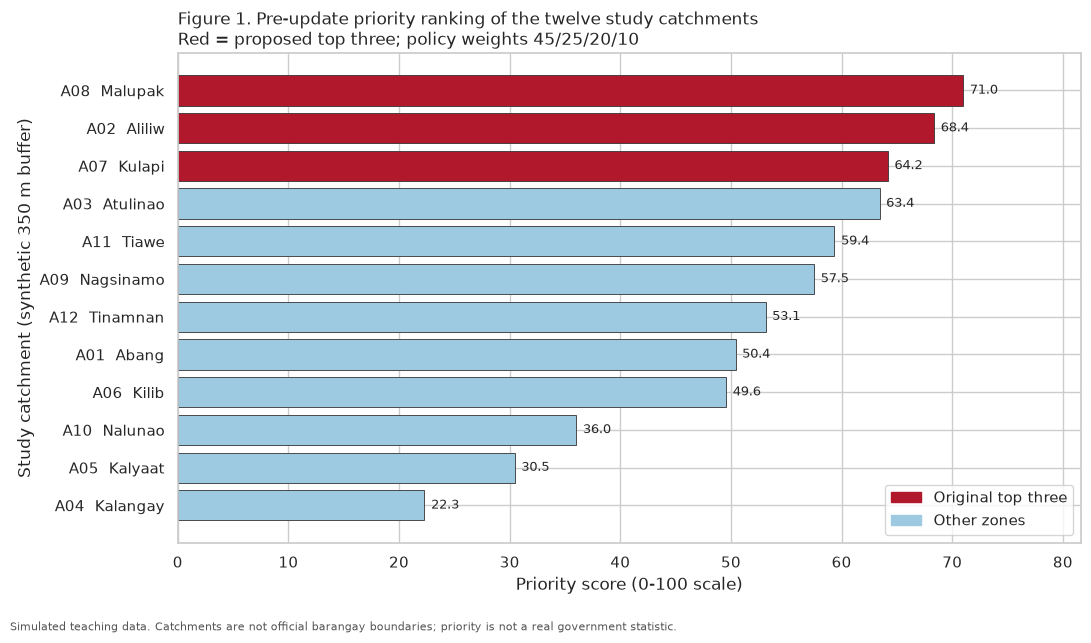

In [13]:
sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(11, 6.2))
ordered = original.sort_values("priority", ascending=True)
colors = ["#b2182b" if rank <= 3 else "#9ecae1" for rank in ordered["rank"]]
bars = ax.barh(ordered["zone_code"] + "  " + ordered["zone_name"], ordered["priority"],
               color=colors, edgecolor="#333333", linewidth=0.6)
for bar, value in zip(bars, ordered["priority"]):
    ax.text(value + 0.6, bar.get_y() + bar.get_height() / 2, f"{value:.1f}",
            va="center", fontsize=9)
ax.set_xlim(0, max(ordered["priority"]) * 1.15)
ax.set_xlabel("Priority score (0-100 scale)")
ax.set_ylabel("Study catchment (synthetic 350 m buffer)")
ax.set_title("Figure 1. Pre-update priority ranking of the twelve study catchments\n"
             "Red = proposed top three; policy weights 45/25/20/10",
             loc="left", fontsize=12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#b2182b", label="Original top three"),
                   plt.Rectangle((0, 0), 1, 1, color="#9ecae1", label="Other zones")],
          loc="lower right", frameon=True)
fig.text(0.01, -0.03,
         "Simulated teaching data. Catchments are not official barangay boundaries; priority is not a real government statistic.",
         fontsize=8, color="#555555")
plt.tight_layout()
plt.show()

### 3.2 What drives the ranking (weighted component decomposition)

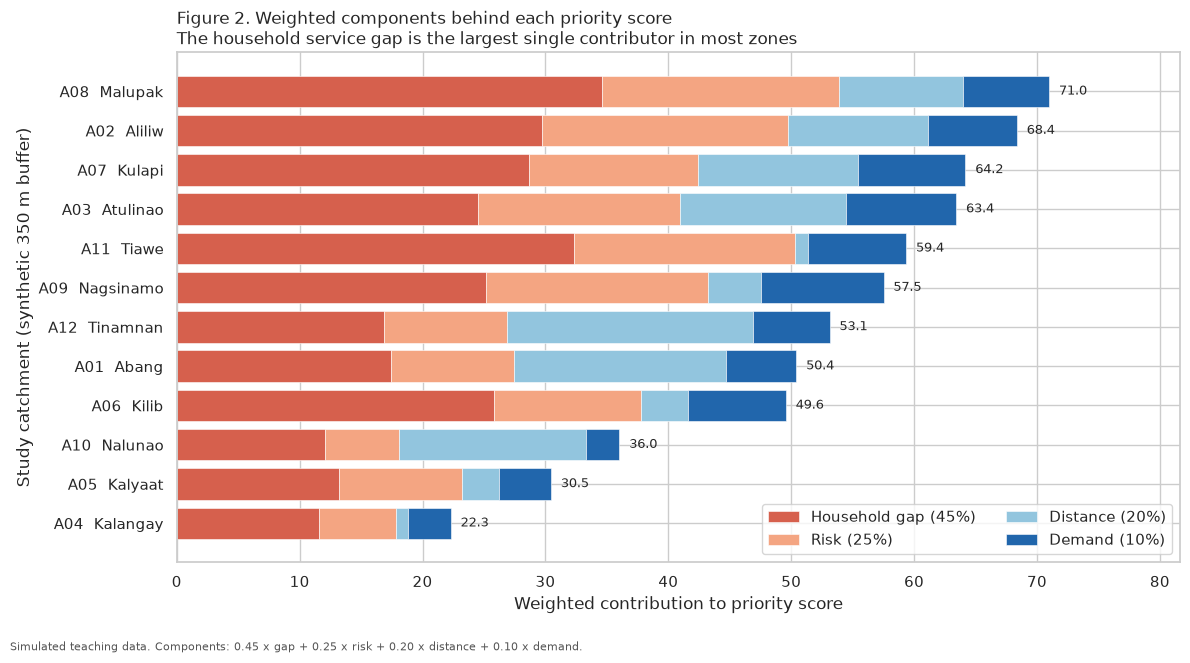

In [14]:
fig, ax = plt.subplots(figsize=(12, 6.4))
ordered = original.sort_values("priority", ascending=True)
labels = ordered["zone_code"] + "  " + ordered["zone_name"]
left = np.zeros(len(ordered))
palette = {"component_gap": "#d6604d", "component_risk": "#f4a582",
           "component_distance": "#92c5de", "component_demand": "#2166ac"}
names = {"component_gap": "Household gap (45%)", "component_risk": "Risk (25%)",
         "component_distance": "Distance (20%)", "component_demand": "Demand (10%)"}
for column in ["component_gap", "component_risk", "component_distance", "component_demand"]:
    ax.barh(labels, ordered[column], left=left, color=palette[column], label=names[column],
            edgecolor="white", linewidth=0.4)
    left += ordered[column].to_numpy()
for i, total in enumerate(ordered["priority"]):
    ax.text(total + 0.8, i, f"{total:.1f}", va="center", fontsize=9)
ax.set_xlabel("Weighted contribution to priority score")
ax.set_ylabel("Study catchment (synthetic 350 m buffer)")
ax.set_title("Figure 2. Weighted components behind each priority score\n"
             "The household service gap is the largest single contributor in most zones",
             loc="left", fontsize=12)
ax.legend(ncol=2, loc="lower right", frameon=True)
ax.set_xlim(0, max(ordered["priority"]) * 1.15)
fig.text(0.01, -0.03,
         "Simulated teaching data. Components: 0.45 x gap + 0.25 x risk + 0.20 x distance + 0.10 x demand.",
         fontsize=8, color="#555555")
plt.tight_layout()
plt.show()

**Reading the charts.** The pre-update ranking is led by A08 (Malupak) and A02 (Aliliw), which combine high household service gaps with high validated risk; A07 (Kulapi) takes third through a large absolute household deficit and strong demand, despite a lower risk score. A03 (Atulinao) is a close fourth, so small changes in facility availability or demand can reorder the top three. Zones near an operational hub (A04, A05, A11) earn little distance credit even when their gap is large, which is a deliberate property of the 20% distance weight.

## 4. Geographic findings | Metric distances and ranking

### Method and CRS

- The catchment polygons are stored in `EPSG:4326` (degrees), which is unsuitable for length or distance arithmetic.
- They are reprojected to **`EPSG:32651` (WGS 84 / UTM zone 51N)**, the metric UTM zone covering Luzon. Coordinates then become metres, so Euclidean distance is meaningful.
- For each zone the **polygon centroid** is computed in the projected CRS (not the GeoJSON anchor point).
- The distance is the minimum straight-line distance from that projected centroid to a facility whose status is `operational`.
- This is **not** road distance, travel time, or accessibility. It ignores terrain, rivers, road networks and barangay boundaries.

The same `score_scenario()` function is reused for the revised scenario, which guarantees that the normalization denominator is recomputed from the twelve zones of whichever facility set is active.

In [15]:
projected_centroids = original.to_crs(METRIC_CRS).geometry.centroid
summary_geo = pd.DataFrame({
    "zone_code": original["zone_code"],
    "centroid_easting_m": projected_centroids.x.round(1).to_numpy(),
    "centroid_northing_m": projected_centroids.y.round(1).to_numpy(),
    "nearest_facility_id": original["nearest_facility_id"],
    "nearest_facility_name": original["nearest_facility_name"],
    "nearest_km": original["nearest_km"].round(3),
    "distance_score": original["distance_score"].round(2),
})
print(summary_geo.to_string(index=False))
print("\nFacilities and their initial status:")
print(facilities_scored[["facility_id", "facility_name", "status"]].to_string(index=False))

zone_code  centroid_easting_m  centroid_northing_m nearest_facility_id               nearest_facility_name  nearest_km  distance_score
      A08         348,047.600        1,559,749.500                 F03 Scenario Assistance Hub — Nagsinamo       1.196          50.610
      A02         345,025.600        1,563,496.100                 F02     Scenario Assistance Hub — Kilib       1.349          57.070
      A07         345,300.600        1,560,795.000                 F02     Scenario Assistance Hub — Kilib       1.541          65.210
      A03         349,916.300        1,561,696.500                 F03 Scenario Assistance Hub — Nagsinamo       1.589          67.230
      A11         348,227.400        1,557,303.500                 F04     Scenario Assistance Hub — Tiawe       0.124           5.230
      A09         349,052.300        1,559,832.000                 F03 Scenario Assistance Hub — Nagsinamo       0.510          21.570
      A12         346,170.300        1,558,212.000     

In [16]:
original_table = original[["rank", "zone_code", "zone_name", "total_households", "households_with_access",
                           "service_gap", "risk_score", "valid_requests", "nearest_facility_id",
                           "nearest_facility_name", "nearest_km", "distance_score", "demand_score", "priority"]].copy()
original_table["priority"] = original_table["priority"].round(3)
print(original_table.to_string(index=False))

 rank zone_code zone_name  total_households  households_with_access  service_gap  risk_score  valid_requests nearest_facility_id               nearest_facility_name  nearest_km  distance_score  demand_score  priority
    1       A08   Malupak               650                 150.000       76.923      77.000              28                 F03 Scenario Assistance Hub — Nagsinamo       1.196          50.614        70.000    70.988
    2       A02    Aliliw               700                 238.000       66.000      80.000              29                 F02     Scenario Assistance Hub — Kilib       1.349          57.070        72.500    68.364
    3       A07    Kulapi              1100                 400.000       63.636      55.000              35                 F02     Scenario Assistance Hub — Kilib       1.541          65.209        87.500    64.178
    4       A03  Atulinao               500                 228.000       54.400      66.000              36                 F03 Sce

## 5. Interactive intelligence map

The map encodes the **priority score** as a colour ramp on the synthetic catchments, shows operational hubs as blue markers, and exposes zone and facility detail in tooltips and popups. Layer controls let the decision maker switch catchments, hubs and the affected-facility layer. A legend and a standing disclaimer are fixed on the map. The HTML is written to disk so it works without the notebook.

In [17]:
def priority_map(data, facilities, affected_ids=None, title="Pre-update priority", zoom=11):
    affected_ids = affected_ids or []
    miny, minx, maxy, maxx = data.total_bounds
    center = [(miny + maxy) / 2, (minx + maxx) / 2]
    m = folium.Map(location=center, zoom_start=zoom, tiles="OpenStreetMap", control_scale=True)

    vmin, vmax = float(data["priority"].min()), float(data["priority"].max())
    cmap = LinearColormap(colors=["#ffffcc", "#fd8d3c", "#800026"], vmin=vmin, vmax=vmax,
                          caption=f"Simulated priority score ({vmin:.1f}-{vmax:.1f})")

    def style(feature):
        value = feature["properties"]["priority"]
        return {"fillColor": cmap(value), "color": "#333333", "weight": 1.4,
                "fillOpacity": 0.68, "dashArray": "4,3"}

    def highlight(feature):
        return {"weight": 3.0, "color": "#111111", "fillOpacity": 0.85}

    zone_layer = folium.FeatureGroup(name="Synthetic study catchments (priorities)", show=True)
    folium.GeoJson(
        data.to_crs(WGS84).to_json(),
        style_function=style,
        highlight_function=highlight,
        tooltip=folium.GeoJsonTooltip(
            fields=["zone_name", "zone_code", "priority", "rank"],
            aliases=["Barangay catchment", "Zone ID", "Priority score", "Rank"],
            localize=True, sticky=True),
        popup=folium.GeoJsonPopup(
            fields=["zone_name", "zone_code", "total_households", "households_with_access",
                    "service_gap", "risk_score", "nearest_facility_id", "nearest_km",
                    "valid_requests", "demand_score", "priority", "rank"],
            aliases=["Barangay catchment", "Zone ID", "Total households", "Households with access",
                     "Service gap (%)", "Validated risk score", "Nearest operational hub",
                     "Straight-line distance (km)", "Eligible distinct requests",
                     "Demand score", "PRIORITY SCORE", "Rank"],
            localize=True).add_to(zone_layer),
    ).add_to(zone_layer)
    zone_layer.add_to(m)

    operational_layer = folium.FeatureGroup(name="Operational assistance hubs (simulated)", show=True)
    affected_layer = folium.FeatureGroup(name="Facility affected by update", show=True)
    for row in facilities.itertuples():
        is_affected = row.facility_id in affected_ids
        is_operational = row.effective_status == "operational"
        color = "#d7191c" if is_affected else ("#2c7bb6" if is_operational else "#7b3294")
        radius = 10 if is_affected else 7
        marker = folium.CircleMarker(
            location=[float(row.latitude), float(row.longitude)],
            radius=radius, color=color, weight=2,
            fill=True, fill_color=color, fill_opacity=0.85,
            tooltip=f"{row.facility_id} | {row.facility_name} | {row.effective_status}",
            popup=folium.Popup(
                f"<b>{row.facility_name}</b><br>"
                f"Facility ID: {row.facility_id}<br>"
                f"Effective status: <b>{row.effective_status}</b><br>"
                f"Coordinates: {float(row.latitude):.4f}, {float(row.longitude):.4f}<br>"
                + ("<br><b>Affected by the sealed operational update.</b>" if is_affected else ""),
                max_width=320))
        if is_affected:
            marker.add_to(affected_layer)
            folium.Marker(
                location=[float(row.latitude), float(row.longitude)],
                icon=folium.DivIcon(html=(
                    f'<div style="font-size:11px;color:#b2182b;font-weight:bold;'
                    f'background:white;border:1px solid #b2182b;border-radius:3px;'
                    f'padding:2px 4px;white-space:nowrap;">UPDATE: {row.facility_id}</div>')),
            ).add_to(affected_layer)
        elif is_operational:
            marker.add_to(operational_layer)
        else:
            marker.add_to(m)
    operational_layer.add_to(m)
    affected_layer.add_to(m)
    cmap.add_to(m)

    legend_html = f'''
    <div style="position: fixed; bottom: 28px; left: 28px; z-index: 9999; font-size: 12px;
                background: white; color: #222; padding: 10px 13px; border: 1px solid #555;
                border-radius: 6px; max-width: 330px; line-height: 1.45;">
      <b>LEGEND</b><br>
      <span style="display:inline-block;width:12px;height:12px;background:#fd8d3c;border:1px solid #333;"></span>
      Catchment fill = priority score (light low, dark high)<br>
      <span style="display:inline-block;width:12px;height:12px;border-radius:50%;background:#2c7bb6;"></span>
      Operational assistance hub<br>
      <span style="display:inline-block;width:12px;height:12px;border-radius:50%;background:#d7191c;"></span>
      Hub affected by operational update<br>
      <span style="display:inline-block;width:12px;height:0;border-top:2px dashed #333;"></span>
      Synthetic 350 m catchment outline<br>
      <hr style="margin:6px 0;">
      <b>DISCLAIMER.</b> Catchments are <b>synthetic 350 m teaching buffers</b>, not official
      barangay boundaries. Facilities, access, risk, requests, distances and priorities are
      <b>simulated</b> for CPE15 and are not LGU, PSA or telecommunications data.
    </div>'''
    m.get_root().html.add_child(folium.Element(legend_html))

    title_html = f'''
    <div style="position: fixed; top: 12px; left: 50px; z-index: 9999; font-size: 15px;
                background: rgba(255,255,255,0.92); color: #111; padding: 7px 12px;
                border: 1px solid #555; border-radius: 5px;">
      <b>Operation Blank Map - Lucban, Quezon</b> - {title}<br>
      <span style="font-size:11px;">Simulated decision support; not an official service assessment.</span>
    </div>'''
    m.get_root().html.add_child(folium.Element(title_html))

    folium.LayerControl(collapsed=False, position="topright").add_to(m)
    return m


original_map = priority_map(original, facilities_scored, title="pre-update priority")
original_map

## 6. Sealed operational update | Apply only when released

The update is supplied by the examiner at 02:25. It is treated as new evidence, not as a source edit: the original CSVs and SQLite file remain untouched. The update is encoded as facility status overrides, and the whole scoring function is re-run. Because the distance denominator is the **maximum zone distance in the active scenario**, closing a hub changes both numerator and denominator and can reorder zones far from the affected facility.

In [18]:
UPDATE_SOURCE = "PENDING - paste the official operational update here when released"
UPDATE_FACILITY_STATUS = {}
UPDATE_EXTRA_REQUESTS = pd.DataFrame(columns=["zone_code", "valid_requests"])
UPDATE_NOTES = "No sealed update has been applied yet."

print("Update source  :", UPDATE_SOURCE)
print("Status changes :", UPDATE_FACILITY_STATUS or "none")
print("Extra demand   :", "none" if UPDATE_EXTRA_REQUESTS.empty else UPDATE_EXTRA_REQUESTS.to_dict("records"))

requests_revised = requests_by_zone.copy()
if not UPDATE_EXTRA_REQUESTS.empty:
    extra = UPDATE_EXTRA_REQUESTS.groupby("zone_code", as_index=False)["valid_requests"].sum()
    requests_revised = requests_revised.merge(extra, on="zone_code", how="outer", suffixes=("", "_extra"))
    requests_revised["valid_requests"] = (requests_revised["valid_requests"].fillna(0)
                                          + requests_revised["valid_requests_extra"].fillna(0))
    requests_revised = requests_revised[["zone_code", "valid_requests"]]

if UPDATE_FACILITY_STATUS or not UPDATE_EXTRA_REQUESTS.empty:
    revised, facilities_revised = score_scenario(
        zones, household, risk, requests_by_zone, raw_facilities,
        status_overrides=UPDATE_FACILITY_STATUS, requests_override=requests_revised)
    affected_ids = [fid for fid, status in UPDATE_FACILITY_STATUS.items() if status != "operational"]
    print("\nRevised priority table:")
    print(revised[["rank", "zone_code", "zone_name", "service_gap", "risk_score", "nearest_km",
                   "distance_score", "valid_requests", "demand_score", "priority"]].to_string(index=False))
    print("\nRevised top three:", revised.head(3)["zone_code"].tolist())
else:
    revised = original.copy()
    facilities_revised = facilities_scored.copy()
    affected_ids = []
    print("\nNo update applied: revised table equals the pre-update table.")

Update source  : PENDING - paste the official operational update here when released
Status changes : none
Extra demand   : none

No update applied: revised table equals the pre-update table.


### 6.1 Before/after comparison

When the update is active, this cell shows rank movement and the delta in priority. A zone can move even if it does not use the affected hub, because the distance normalisation denominator is recomputed across all twelve zones.

In [19]:
if (UPDATE_FACILITY_STATUS or not UPDATE_EXTRA_REQUESTS.empty):
    comparison = original[["zone_code", "zone_name", "priority", "rank", "nearest_facility_id",
                           "nearest_km", "distance_score"]].merge(
        revised[["zone_code", "priority", "rank", "nearest_facility_id", "nearest_km", "distance_score"]],
        on="zone_code", suffixes=("_original", "_revised"))
    comparison["priority_delta"] = comparison["priority_revised"] - comparison["priority_original"]
    comparison["rank_change"] = comparison["rank_original"] - comparison["rank_revised"]
    comparison = comparison.sort_values("rank_revised")
    print(comparison.round(3).to_string(index=False))

    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(comparison))
    width = 0.38
    ax.bar(x - width / 2, comparison["priority_original"], width, label="Pre-update", color="#9ecae1")
    ax.bar(x + width / 2, comparison["priority_revised"], width, label="Revised", color="#b2182b")
    ax.set_xticks(x)
    ax.set_xticklabels(comparison["zone_code"], rotation=0)
    ax.set_ylabel("Priority score (0-100 scale)")
    ax.set_xlabel("Study catchment")
    ax.set_title("Figure 3. Priority before and after the sealed operational update", loc="left")
    ax.legend(frameon=True)
    fig.text(0.01, -0.03, "Simulated teaching data. Recalculated after the facility update.", fontsize=8, color="#555555")
    plt.tight_layout()
    plt.show()
else:
    comparison = pd.DataFrame()
    print("Comparison will appear once the sealed update is entered above.")

Comparison will appear once the sealed update is entered above.


### 6.2 Revised interactive map

The revised map uses the same encoding but flags every facility affected by the update and repaints the catchments with recalculated priorities.

In [20]:
if (UPDATE_FACILITY_STATUS or not UPDATE_EXTRA_REQUESTS.empty):
    revised_map = priority_map(revised, facilities_revised, affected_ids=affected_ids,
                               title="revised priority after operational update")
    revised_map
else:
    revised_map = None
    print("The revised map appears once the sealed update is entered.")

The revised map appears once the sealed update is entered.


## 7. Final recommendation and exports

The exported CSV contains all twelve zones with validated pre-update and revised scores, ranks and spatial metrics. The exported HTML is the self-contained revised map and can be opened outside the notebook. Original evidence is never modified.

In [21]:
final_cols = ["zone_code", "zone_name", "psgc_code", "total_households", "households_with_access",
              "service_gap", "risk_score", "valid_requests",
              "nearest_facility_id", "nearest_facility_name", "nearest_km", "distance_score",
              "demand_score", "priority", "rank"]
processed = original[final_cols].rename(columns={
    "nearest_facility_id": "nearest_operational_facility_id",
    "nearest_facility_name": "nearest_operational_facility_name",
    "nearest_km": "nearest_operational_facility_distance_km",
    "demand_score": "request_demand_score",
    "priority": "priority_score",
    "rank": "priority_rank",
})
processed = processed.rename(columns={
    "service_gap": "household_service_gap",
    "risk_score": "validated_risk_score",
    "valid_requests": "valid_request_count",
    "distance_score": "distance_score",
})

if (UPDATE_FACILITY_STATUS or not UPDATE_EXTRA_REQUESTS.empty):
    revised_cols = revised[["zone_code", "nearest_facility_id", "nearest_km", "distance_score",
                            "valid_requests", "demand_score", "priority", "rank"]]
    revised_cols = revised_cols.rename(columns={
        "nearest_facility_id": "revised_nearest_facility_id",
        "nearest_km": "revised_nearest_distance_km",
        "distance_score": "revised_distance_score",
        "valid_requests": "revised_valid_request_count",
        "demand_score": "revised_request_demand_score",
        "priority": "revised_priority_score",
        "rank": "revised_priority_rank",
    })
    processed = processed.merge(revised_cols, on="zone_code", how="left")

processed = processed.sort_values("priority_rank").reset_index(drop=True)
CSV_PATH = OUT_DIR / "CPE15_PROCESSED.csv"
HTML_PATH = OUT_DIR / "CPE15_FINAL_MAP.html"
processed.to_csv(CSV_PATH, index=False)
print(f"Saved {CSV_PATH.name}: {processed.shape[0]} zones x {processed.shape[1]} columns")
print(processed.round(3).to_string(index=False))

Saved CPE15_PROCESSED.csv: 12 zones x 15 columns
zone_code zone_name  psgc_code  total_households  households_with_access  household_service_gap  validated_risk_score  valid_request_count nearest_operational_facility_id   nearest_operational_facility_name  nearest_operational_facility_distance_km  distance_score  request_demand_score  priority_score  priority_rank
      A08   Malupak 0405623022               650                 150.000                 76.923                77.000                   28                             F03 Scenario Assistance Hub — Nagsinamo                                     1.196          50.614                70.000          70.988              1
      A02    Aliliw 0405623002               700                 238.000                 66.000                80.000                   29                             F02     Scenario Assistance Hub — Kilib                                     1.349          57.070                72.500          68.364             

In [22]:
map_to_export = revised_map if revised_map is not None else original_map
map_to_export.save(str(HTML_PATH))
assert CSV_PATH.exists() and CSV_PATH.stat().st_size > 0
assert HTML_PATH.exists() and HTML_PATH.stat().st_size > 0
check = pd.read_csv(CSV_PATH)
assert len(check) == 12 and check["zone_code"].is_unique
print(f"Validated export: {CSV_PATH.resolve()} ({CSV_PATH.stat().st_size:,} bytes)")
print(f"Validated export: {HTML_PATH.resolve()} ({HTML_PATH.stat().st_size:,} bytes)")
print("All twelve zones present in the processed CSV. HTML map is self-contained.")

Validated export: /home/rollie/dev/CPE15/activity/final-project/Operation Blank Map - STUDENT PACKAGE/answers/CPE15_PROCESSED.csv (2,199 bytes)
Validated export: /home/rollie/dev/CPE15/activity/final-project/Operation Blank Map - STUDENT PACKAGE/answers/CPE15_FINAL_MAP.html (96,591 bytes)
All twelve zones present in the processed CSV. HTML map is self-contained.


## 8. Answers to the six casefile questions

**1. What source information is trustworthy, and what requires correction or qualification?**
Trustworthy: the twelve zone IDs/names and their PSGC codes in `zones.geojson`, and the structure of the six evidence files. Requires correction: the `A-03` alias (FN-01), duplicate A07 household row, blank A06 access (FN-02), impossible A11 access of 1220 (FN-03), conflicting A09 risk of 72/96 (FN-04), three duplicate request IDs, and the cancellation/invalid request statuses. Requires qualification: all coordinates are approximate anchors, the catchments are synthetic 350 m buffers rather than official boundaries, and every household, risk, request and facility value is simulated.

**2. Which three zones rank highest before the update?**
See the Figure 1 output above; the computed pre-update top three is A08 Malupak, A02 Aliliw and A07 Kulapi.

**3. What factors explain those rankings?**
The 45% household service gap dominates: A08 has the second-largest gap and high risk, while A02 combines a large gap with the highest validated risk. A07's large absolute household deficit and strong eligible demand lift it to third. Figure 2 shows each zone's weighted decomposition.

**4. Where are the zones in relation to operational facilities?**
All five supplied hubs are operational in the pre-update scenario. Distances are straight-line metres from projected centroids, with A12 Tinamnan farthest and A04/A11 nearest. Proximity does not mean road access or travel time.

**5. Does the new evidence change the top three, and why?**
This is answered in Section 6 once the sealed update is applied. The section prints the revised ranking, the priority deltas, the affected facility and the recalculated normalisation.

**6. What are the limitations?**
Synthetic catchments are not barangay boundaries; centroids may fall away from actual settlement; straight-line distance ignores terrain and roads; simulated inputs carry unknown error; the policy weights are arbitrary teaching values; and missing values were repaired only where the field bulletin authorised it. Results should be read as a reproducible classroom decision aid, not an LGU assessment.